# DWD-Wetterdaten: Berlin 2020 bis heute

Dieses Notebook lädt die vorbereitete CSV-Datei der DWD-Station **Berlin-Dahlem (FU), Stations-ID 00403**. Es prüft die Datenverfügbarkeit und stellt anschließend die täglichen Durchschnittstemperaturen der einzelnen Jahre als farbige, übereinandergelegte Linien dar. Die CSV deckt den Zeitraum **01.01.2020 bis 01.11.2026** ab, dem neuesten verfügbaren DWD-Datum zum Download.

## Datenquelle und Station

Die CSV wurde aus den historischen und aktuellen Tageswerten des **DWD Climate Data Center (CDC)** zusammengeführt. Berlin-Dahlem liegt bei 52.4537° N, 13.3017° E. Die Sonnenscheindauer ist im DWD-Feld `SDK` in Stunden erfasst. Temperaturen stehen in °C, Niederschlag in mm.

Berlin-Tempelhof (00433) wurde nicht verwendet: Dort endet die Sonnenscheindauer-Reihe bereits 2022. Berlin-Dahlem liefert alle fünf gewünschten Merkmale bis zum aktuellen Archivstand, allerdings mit einzelnen fehlenden Tageswerten. Fehlwerte sind in der CSV leer und wurden nicht ergänzt.

Quelle: [DWD Open Data, tägliche Klimawerte](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/)

In [2]:
import csv
from pathlib import Path

csv_pfad = Path("DWD_Berlin_Dahlem_2020_bis_2026-11-01.csv")
with csv_pfad.open(encoding="utf-8", newline="") as csv_datei:
    daten = list(csv.DictReader(csv_datei))

print(f"Datei: {csv_pfad.name}")
print(f"Tageszeilen: {len(daten)}")
print(f"Zeitraum: {daten[0]['datum']} bis {daten[-1]['datum']}")
print("Erste fünf Zeilen:")
for eintrag in daten[:5]:
    print(eintrag)

Datei: DWD_Berlin_Dahlem_2020_bis_2026-11-01.csv
Tageszeilen: 2497
Zeitraum: 2020-01-01 bis 2026-11-01
Erste fünf Zeilen:
{'datum': '2020-01-01', 'temp_min_c': '-2.8', 'temp_max_c': '5.0', 'temp_durch_c': '1.8', 'niederschlagsmenge_mm': '0.0', 'sonnenstunden_h': '2.900'}
{'datum': '2020-01-02', 'temp_min_c': '-4.1', 'temp_max_c': '6.2', 'temp_durch_c': '-0.3', 'niederschlagsmenge_mm': '0.0', 'sonnenstunden_h': '7.500'}
{'datum': '2020-01-03', 'temp_min_c': '0.8', 'temp_max_c': '6.9', 'temp_durch_c': '4.3', 'niederschlagsmenge_mm': '4.4', 'sonnenstunden_h': '0.000'}
{'datum': '2020-01-04', 'temp_min_c': '1.7', 'temp_max_c': '5.6', 'temp_durch_c': '4.1', 'niederschlagsmenge_mm': '3.0', 'sonnenstunden_h': '0.000'}
{'datum': '2020-01-05', 'temp_min_c': '-1.4', 'temp_max_c': '3.6', 'temp_durch_c': '1.4', 'niederschlagsmenge_mm': '0.0', 'sonnenstunden_h': '2.100'}


## Verfügbarkeit der Merkmale prüfen

Der Zeitraum umfasst 2497 Kalendertage. Die folgende Zelle zählt gültige Werte und zeigt den jeweiligen ersten und letzten verfügbaren Tag. Leere CSV-Felder gelten als fehlend.

In [ ]:
merkmale = {
    "temp_min_c": "Minimum (°C)",
    "temp_max_c": "Maximum (°C)",
    "temp_durch_c": "Tagesmittel (°C)",
    "niederschlagsmenge_mm": "Niederschlag (mm)",
    "sonnenstunden_h": "Sonnenscheindauer (h)",
}

for spalte, bezeichnung in merkmale.items():
    verfuegbar = [eintrag for eintrag in daten if eintrag[spalte]]
    erster_tag = verfuegbar[0]["datum"] if verfuegbar else "keine Werte"
    letzter_tag = verfuegbar[-1]["datum"] if verfuegbar else "keine Werte"
    print(
        f"{bezeichnung}: {len(verfuegbar)}/{len(daten)} Tage; "
        f"von {erster_tag} bis {letzter_tag}"
    )

## Jahresverläufe der Durchschnittstemperatur

Das Liniendiagramm legt die Tagesmitteltemperatur (`temp_durch_c`) der einzelnen Jahre auf dieselbe Monatsachse. Jedes Jahr erhält eine eigene Farbe. Fehlende Messwerte werden als Lücken dargestellt; das laufende Jahr 2026 ist nur bis zum letzten verfügbaren DWD-Tag enthalten.

2020: Jahresmittel 11.1 °C
2021: Jahresmittel 10.0 °C
2022: Jahresmittel 11.1 °C
2023: Jahresmittel 11.2 °C
2024: Jahresmittel 11.8 °C
2025: Jahresmittel 10.9 °C
2026 (Teiljahr): Jahresmittel 11.6 °C


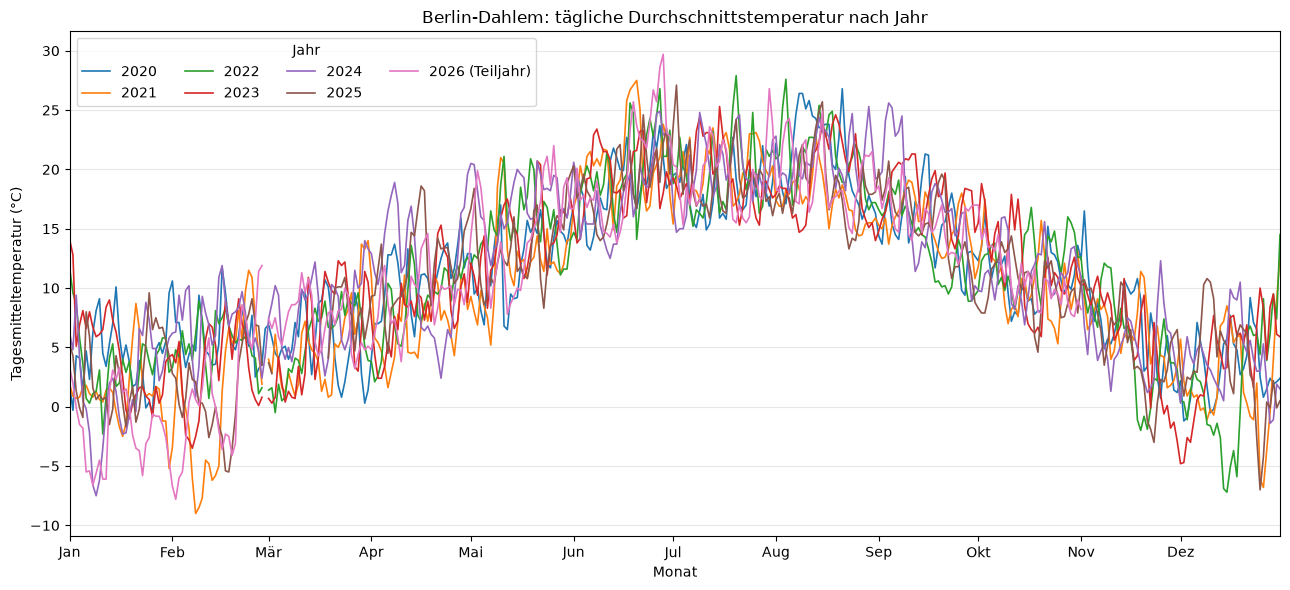

In [4]:
import matplotlib.pyplot as plt
from datetime import date, timedelta

jahreswerte = {}
for eintrag in daten:
    if eintrag["temp_durch_c"]:
        messdatum = date.fromisoformat(eintrag["datum"])
        jahreswerte.setdefault(messdatum.year, {})[
            (messdatum.month, messdatum.day)
        ] = float(eintrag["temp_durch_c"])

kalenderdaten = [date(2000, 1, 1) + timedelta(days=tag) for tag in range(366)]
monate = [date(2000, monat, 1) for monat in range(1, 13)]
monatsnamen = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun", "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]

fig, ax = plt.subplots(figsize=(13, 6))
farben = plt.get_cmap("tab10")
letztes_jahr = max(jahreswerte)

for farbindex, jahr in enumerate(sorted(jahreswerte)):
    werte = [
        jahreswerte[jahr].get((tag.month, tag.day), float("nan"))
        for tag in kalenderdaten
    ]
    label = f"{jahr}"
    if jahr == letztes_jahr and len(jahreswerte[jahr]) < 365:
        label += " (Teiljahr)"
    ax.plot(
        kalenderdaten,
        werte,
        color=farben(farbindex % 10),
        linewidth=1.2,
        label=label,
    )
    gueltige_werte = list(jahreswerte[jahr].values())
    print(f"{label}: Jahresmittel {sum(gueltige_werte) / len(gueltige_werte):.1f} °C")

ax.set_title("Berlin-Dahlem: tägliche Durchschnittstemperatur nach Jahr")
ax.set_xlabel("Monat")
ax.set_ylabel("Tagesmitteltemperatur (°C)")
ax.set_xticks(monate, monatsnamen)
ax.set_xlim(kalenderdaten[0], kalenderdaten[-1])
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Jahr", ncols=4)
fig.tight_layout()
plt.show()
plt.close(fig)
del ax, farben, farbindex, fig, gueltige_werte, jahr, jahreswerte, kalenderdaten, label, letztes_jahr, messdatum, monate, monatsnamen, werte